# 01 – XCL1 senders and XCR1 receivers: which cells, from where?

**Claim tested** (Park *et al.* 2020, main text on Fig. 4D and fig. S26):

> "We also noted that GNG4⁺CD8αα⁺ T(I) cells expressed XCL1, which may be involved in the recruitment of
> XCR1-expressing DC1 cells. Our analysis shows that XCL1 is expressed most highly by CD8αα⁺ T(I) cells and at a lower
> level by NK cells (fig. S26). The location of CD8αα⁺ T(I) cells in the perimedullary region suggests a potential relay
> of signals from CD8αα⁺ T(I) cells to recruit XCR1⁺ DC1 cells into the medulla, where these cells are activated and
> up-regulate CCR7 (Fig. 4D)."

**Question.** Which cells enter the CausalCCC run for this claim, where do they come from (donor, stage, chemistry,
sort), and does the claim's expression pattern hold in the public data?

Decisions taken before this notebook (same pipeline as `notebooks/thymus_early`, notebooks 02–05):
- **senders** = CD8αα(I) + NK (the two XCL1 sources named in the text), group `cd8aa_nk`;
- **receivers** = DC1 + aDC1 (resting and activated DC1; the activation is part of the claim), group `dc1`;
- **all ages pooled**; donor, chemistry and stage will be variables of the network;
- counts from the raw-count h5ad, labels from the fig1 `.obs` (thymus case 1, notebook 01).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import anndata as ad
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

ROOT = Path("../..")
THY = ROOT / "data/thymus"
OUT = ROOT / "results/thymus_case2_xcl1/01_cell_populations"
FIG = ROOT / "results/figures/thymus_case2_xcl1"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

annot = ad.read_h5ad(THY / "thymus_annotated_matrix_files/HTA08.v01.A05.Science_human_fig1.h5ad", backed="r")
raw = ad.read_h5ad(THY / "HTA07.A01.v02.entire_data_raw_count.h5ad", backed="r")

SENDERS = ["CD8αα(I)", "NK"]
RECEIVERS = ["DC1", "aDC1"]
ORDER = SENDERS + RECEIVERS
GROUP = {p: "cd8aa_nk" for p in SENDERS} | {p: "dc1" for p in RECEIVERS}

# Annotation and design columns from fig1; per-cell QC values (computed by the authors on raw counts) from the raw file
cells = annot.obs[["Anno_level_1", "Anno_level_5", "Anno_stage", "donor", "Age", "method", "sort", "Source"]].astype(str)
cells = cells.join(raw.obs[["n_counts", "n_genes", "mito"]])
cells["stage"] = cells.Anno_stage.str.rsplit("_", n=1).str[-1]      # early / middle / late (age bins, notebook 01 of case 1)

sel = cells[cells.Anno_level_5.isin(ORDER)].copy()
sel["group"] = sel.Anno_level_5.map(GROUP)
pd.crosstab([sel.group, sel.Anno_level_5], sel.stage, margins=True)[["early", "middle", "late", "All"]]

/tmp/ipykernel_413/4101692408.py:17: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  annot = ad.read_h5ad(THY / "thymus_annotated_matrix_files/HTA08.v01.A05.Science_human_fig1.h5ad", backed="r")


/tmp/ipykernel_413/4101692408.py:18: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  raw = ad.read_h5ad(THY / "HTA07.A01.v02.entire_data_raw_count.h5ad", backed="r")


stage                  early  middle  late   All
group    Anno_level_5                           
cd8aa_nk CD8αα(I)        360    1778  1761  3899
         NK              995     380   240  1615
dc1      DC1             400     813   170  1383
         aDC1             20      97    18   135
All                     1775    3068  2189  7032

## 1. Does the expression pattern of the claim hold?

Fig. S26 ranks the populations by XCL1. We recompute, for every `Anno_level_5` population, the fraction of cells with
XCL1 (and XCL2, its close paralogue, which binds the same receptor) and the mean expression on the authors' scale
(log1p of counts per 100,000, the fig1 matrix). The same is done for XCR1 and DC activation / migration genes.
The fig1 matrix is read in row chunks, so only the selected genes are kept in memory.

`mean_linear` is the mean of the normalised counts *without* the log (counts per 100,000). CellPhoneDB, and so
Table S5, averages expression on that scale, where a few cells with very high values weigh more.

In [2]:
GENES = ["XCL1", "XCL2", "XCR1", "CCR7", "LAMP3", "CD40", "CD80", "CD86", "IL12B", "GNG4"]
gene_idx = []
for g in GENES:
    hits = np.flatnonzero(annot.var_names == g)
    assert len(hits) == 1, g                    # none of these symbols is duplicated in the matrix
    gene_idx.append(hits[0])

chunks = []
for start in range(0, annot.n_obs, 25_000):
    block = annot.X[start:start + 25_000]
    chunks.append(np.asarray(block[:, gene_idx].toarray()))
logexpr = pd.DataFrame(np.vstack(chunks), index=annot.obs_names, columns=GENES)
pop_all = cells.loc[logexpr.index, "Anno_level_5"]

def level_table(genes):
    out = {}
    for g in genes:
        x = logexpr[g]
        out[(g, "frac")] = (x > 0).groupby(pop_all).mean()
        out[(g, "mean")] = x.groupby(pop_all).mean()
        out[(g, "mean_if>0")] = x.where(x > 0).groupby(pop_all).mean()
        out[(g, "mean_linear")] = np.expm1(x).groupby(pop_all).mean()   # counts per 100,000, no log
    t = pd.DataFrame(out)
    t[("", "n_cells")] = pop_all.value_counts()
    return t

xcl = level_table(["XCL1", "XCL2"])
xcl.sort_values(("XCL1", "mean"), ascending=False).head(12).round(2)

XCL1                              XCL2                                    
              frac  mean mean_if>0 mean_linear  frac  mean mean_if>0 mean_linear n_cells
Anno_level_5                                                                            
NK            0.67  2.88      4.32   97.839996  0.84  3.73      4.42  118.970001    1615
NKT           0.57  2.34      4.10   60.060001  0.48  1.89      3.94   45.529999     349
ILC3          0.33  1.33      4.00   39.470001  0.37  1.49      4.00   39.240002     561
CD8αα(II)     0.28  1.11      4.01   24.980000  0.17  0.64      3.66   11.230000    2884
CD8αα(I)      0.18  0.97      5.33   78.519997  0.09  0.43      4.73   24.709999    3899
CD8+Tmem      0.18  0.71      4.02   16.410000  0.15  0.57      3.86   12.210000    1644
T(agonist)    0.08  0.34      4.44   14.290000  0.03  0.14      4.21    6.240000    3614
aDC2          0.07  0.25      3.55    5.910000  0.03  0.09      3.51    1.150000     158
mTEC(II)      0.05  0.15      2.87    3.040000  0.04  0.12      2.81    3.030000     808
aDC1          0.04  0.14      3.15    1.160000  0.01  0.03      3.79    0.320000     135
CD4+PD1       0.04  0.12      2.84    0.870000  0.00  0.00       NaN    0.000000      69
Th17          0.03  0.12      3.69    2.750000  0.02  0.07      3.25    1.450000     727

In [3]:
# Same ranking, restricted to the cells of the early, middle and late stages separately (XCL1 mean, populations >= 30 cells)
by_stage = {}
for st in ["early", "middle", "late"]:
    m = (cells.loc[logexpr.index, "stage"] == st).values
    x, p = logexpr.loc[m, "XCL1"], pop_all[m]
    n = p.value_counts()
    by_stage[st] = x.groupby(p).mean()[n[n >= 30].index].sort_values(ascending=False).head(6).round(2)
pd.concat({st: s.reset_index().set_axis(["population", "XCL1 mean"], axis=1) for st, s in by_stage.items()}, axis=1)

early               middle                  late          
   population XCL1 mean population XCL1 mean  population XCL1 mean
0         NKT      3.09         NK      3.84          NK      3.60
1          NK      2.34        NKT      2.19        ILC3      2.37
2   CD8αα(II)      1.58   CD8αα(I)      1.25   CD8αα(II)      1.02
3    CD8αα(I)      1.33  CD8αα(II)      1.14    CD8+Tmem      0.70
4        ILC3      1.09   CD8+Tmem      0.87    CD8αα(I)      0.62
5  T(agonist)      0.54       ILC3      0.53  T(agonist)      0.30

In [4]:
# Receiver side: XCR1 and activation / migration genes in the DC populations
dc_pops = ["DC1", "aDC1", "DC2", "aDC2", "aDC3", "pDC"]
recv = level_table(["XCR1", "CCR7", "LAMP3", "CD40", "CD80", "CD86", "IL12B"])
recv.loc[dc_pops, [c for c in recv.columns if c[1] in ("frac", "n_cells")]].round(2)

,XCR1,CCR7,LAMP3,CD40,CD80,CD86,IL12B,
,frac,frac,frac,frac,frac,frac,frac,n_cells
Anno_level_5,,,,,,,,
DC1,0.56,0.04,0.09,0.43,0.09,0.52,0.03,1383
aDC1,0.02,0.90,0.93,0.90,0.70,0.63,0.47,135
DC2,0.00,0.08,0.14,0.34,0.06,0.67,0.00,770
aDC2,0.00,0.78,0.78,0.77,0.39,0.54,0.01,158
aDC3,0.01,0.90,0.87,0.60,0.53,0.60,0.07,179
pDC,0.00,0.22,0.02,0.15,0.00,0.17,0.00,1048


**Reading.**
- On the fraction of expressing cells and on the mean over all cells, XCL1 is **not** highest in CD8αα(I): NK (67% of
  cells, mean 2.88), NKT, ILC3 and CD8αα(II) are all above CD8αα(I) (18%, mean 0.97). XCL2 follows the same order.
- CD8αα(I) does have the **highest level among the cells that express XCL1** (5.33, against 4.32 in NK): few
  CD8αα(I) cells express XCL1, but those express a lot. On the linear scale used by CellPhoneDB (`mean_linear`), these
  cells move CD8αα(I) from fifth to **second** (78.5 per 100,000), still behind NK (97.8).
- So the statement "expressed most highly by CD8αα⁺ T(I) cells" holds only for the level within expressing cells. Fig. S26
  was drawn from the authors' T-cell object and S5 from an earlier annotation (notebook 02), neither reanalysed here.
- By stage, NK has the highest mean in the middle and late stages; CD8αα(I) is third in the middle stage and fifth in
  the late stage.
- Receivers: XCR1 marks resting DC1 (56% of DC1, 2% of aDC1), whereas CCR7, LAMP3, CD40, CD80 and IL12B mark aDC1
  (47–93%). The "recruit XCR1⁺ DC1, which are then activated and up-regulate CCR7" sequence is thus a change of state
  between the two receiver populations. This is why both are receivers and why `population` is a network variable.
- Consequence for the run: with NK among the senders, XCL1 in the sender group will mostly come from NK cells. The
  `population` variable lets MIIC show whether XCL1 depends on the NK / CD8αα(I) distinction.

## 2. Where do the selected cells come from?

In [5]:
ages = cells.groupby("donor").Age.first()
def age_in_weeks(a):
    v = float(a[:-1])
    return v if a.endswith("w") else 40 + v * 4.35 if a.endswith("m") else 40 + v * 52
donor_order = sorted(sel.donor.unique(), key=lambda d: age_in_weeks(ages[d]))

by_donor = pd.crosstab(sel.Anno_level_5, sel.donor).reindex(index=ORDER, columns=donor_order)
by_donor.columns = [f"{d} ({ages[d]})" for d in donor_order]
by_donor.T

Anno_level_5,CD8αα(I),NK,DC1,aDC1
C40 (7w),0,659,229,4
C41 (8w),49,52,81,5
F22 (9w),22,59,14,5
C34 (9w),2,1,6,0
F74 (10w),116,61,28,3
F23 (11w),44,92,18,0
F64 (11w),127,71,24,3
F45 (12w),105,42,15,0
F67 (12w),347,67,101,34
F38 (13w),97,33,74,6


In [6]:
pd.concat({"stage": pd.crosstab(sel.Anno_level_5, sel.stage)[["early", "middle", "late"]],
           "chemistry": pd.crosstab(sel.Anno_level_5, sel.method),
           "sort": pd.crosstab(sel.Anno_level_5, sel["sort"])}, axis=1).reindex(ORDER)

stage              chemistry       sort                                
             early middle  late      3GEX  5GEX  45N 45NM  45P CD3N CD3P EPCAM   TOT
Anno_level_5                                                                        
CD8αα(I)       360   1778  1761      1436  2463   30    0  739   32  815    50  2233
NK             995    380   240      1048   567   66   32  200   57    3     5  1252
DC1            400    813   170       835   548   44    4  539   77    0     9   710
aDC1            20     97    18        40    95    0    1   46    1    0     4    83

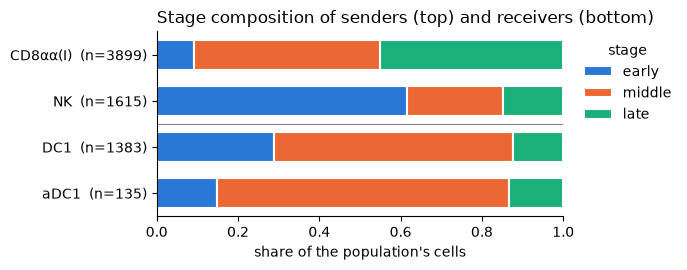

In [7]:
# Share of each population's cells by stage; white gaps separate the segments
stage_share = pd.crosstab(sel.Anno_level_5, sel.stage, normalize="index").reindex(index=ORDER)[["early", "middle", "late"]]
colors = {"early": "#2a78d6", "middle": "#eb6834", "late": "#1baf7a"}
fig, ax = plt.subplots(figsize=(7, 2.8))
left = np.zeros(len(ORDER))
for st in ["early", "middle", "late"]:
    ax.barh(ORDER, stage_share[st], left=left, color=colors[st], edgecolor="white", linewidth=1.5, height=0.65,
            label=st)
    left += stage_share[st].values
n = sel.Anno_level_5.value_counts()
ax.set_yticks(range(len(ORDER)), [f"{p}  (n={n[p]})" for p in ORDER])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("share of the population's cells")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.axhline(1.5, color="0.5", linewidth=0.8)
ax.legend(title="stage", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
ax.set_title("Stage composition of senders (top) and receivers (bottom)", loc="left")
fig.tight_layout()
fig.savefig(FIG / "01_stage_composition.png", dpi=200, bbox_inches="tight")
plt.show()

**Reading.**
- CD8αα(I) cells come from the middle and late stages (91%) and are absent from C40. NK cells are mostly early (62%),
  and 41% of them come from C40 alone. DC1 is mainly middle stage; aDC1 is small (135 cells), mostly middle stage
  (F67, F30).
- So, within the senders, *population* is linked to *stage*: an NK vs CD8αα(I) difference is also an early vs later
  difference. Stage and donor are therefore network variables, but they cannot fully separate the two.
- Chemistry is mixed in every population (CD8αα(I) and aDC1 are mostly 5′). CD8αα(I) cells come partly from CD3⁺ (815)
  and CD45⁺ (739) sorts, the rest from total thymus.

## 3. Quality per population and chemistry

In [8]:
qc = sel.groupby(["Anno_level_5", "method"]).agg(
    cells=("n_genes", "size"), median_genes=("n_genes", "median"),
    median_counts=("n_counts", "median"), median_mito_pct=("mito", lambda x: 100 * x.median()))
qc.reindex(ORDER, level=0).round(1)

cells  median_genes  median_counts  median_mito_pct
Anno_level_5 method                                                     
CD8αα(I)     3GEX     1436        1353.0         3207.5              2.4
             5GEX     2463        1598.0         3474.0              3.0
NK           3GEX     1048        1581.0         4466.5              2.2
             5GEX      567        1597.0         4313.0              4.2
DC1          3GEX      835        2688.0        11616.0              2.5
             5GEX      548        2903.5        14806.0              3.7
aDC1         3GEX       40        2188.5        13580.0              2.5
             5GEX       95        1857.0         9288.0              4.2

**Reading.**
- The sender populations are shallow (median about 3,200–4,500 counts and 1,350–1,600 genes), the DC populations deeper
  (9,000–15,000 counts). This difference is between groups, and CausalCCC learns each group's network separately.
- Within a population, 5′ cells have a higher mitochondrial fraction (as in thymus case 1), and aDC1 5′ cells have
  fewer counts. Chemistry has a modest technical effect, so `method` stays a network variable.

In [9]:
# Cells selected for the next notebooks (one row per cell)
cols = ["Anno_level_5", "group", "donor", "Age", "stage", "method", "sort", "Source", "n_counts", "n_genes", "mito"]
sel[cols].rename(columns={"Anno_level_5": "population"}).to_csv(OUT / "selected_cells.csv")
xcl.round(4).to_csv(OUT / "xcl_expression_by_population.csv")
print(len(sel), "cells written to", OUT / "selected_cells.csv")

7032 cells written to ../../results/thymus_case2_xcl1/01_cell_populations/selected_cells.csv


## Summary

| | |
|---|---|
| Senders (`cd8aa_nk`) | CD8αα(I) 3,899 · NK 1,615 |
| Receivers (`dc1`) | DC1 1,383 · aDC1 135 |
| Ages | all pooled (7 PCW – 35 years), 23 donors |
| Claim check | XCL1 level among expressing cells is highest in CD8αα(I); on average NK is highest (log or linear scale), CD8αα(I) is 2nd on the linear scale and 5th on the log scale |
| Receiver states | XCR1 in DC1 (56%); CCR7 / LAMP3 / CD40 / CD80 / IL12B in aDC1 (47–93%) |
| Known limits | NK ≈ early stage and donor C40, CD8αα(I) ≈ middle/late; aDC1 small (135 cells) |

Next (notebook 02): candidate ligand–receptor pairs from senders to receivers.